# K-Fold и выбор архитектуры

Сравним MLP с 4, 8 и 16 скрытыми нейронами с помощью пяти разбиений K-Fold на Linnerud. Для каждого выхода рассчитаем среднюю MSE и разброс по фолдам.


## Ход работы

Формируем пять одинаковых разбиений Linnerud для сравниваемых архитектур. В каждом фолде оставляем 16 наблюдений для обучения и четыре для проверки. Нормализаторы обучаем заново на тренировочной части фолда, после чего создаём новую модель и обучаем её 300 эпох с Adam.

Повторяем процедуру для сетей `3 → 4 → 3`, `3 → 8 → 3` и `3 → 16 → 3`. Перед расчётом ошибок возвращаем предсказания к исходному масштабу целей. Для каждой архитектуры собираем пять значений MSE по каждому выходу и сравниваем их среднее и стандартное отклонение: так видны и качество, и чувствительность к разбиению.


### K-Fold для сети 3 → 4 → 3

Сначала создаём слабую базовую архитектуру с четырьмя скрытыми нейронами. На каждом из пяти разбиений нормализаторы `X` и `y` обучаются только по 16 тренировочным объектам; проверочные четыре объекта не участвуют в вычислении `fit`.

Обучение: 4 нейронов
X: (20, 3)
y: (20, 3)

========== FOLD 1 ==========
Train: 16
Validation: 4
Weight: MSE = 878.3684
Waist: MSE = 8.6329
Pulse: MSE = 183.9967

========== FOLD 2 ==========
Train: 16
Validation: 4
Weight: MSE = 183.3678
Waist: MSE = 2.0142
Pulse: MSE = 108.5865

========== FOLD 3 ==========
Train: 16
Validation: 4
Weight: MSE = 522.9396
Waist: MSE = 20.3371
Pulse: MSE = 124.2984

========== FOLD 4 ==========
Train: 16
Validation: 4
Weight: MSE = 2129.3579
Waist: MSE = 16.1371
Pulse: MSE = 178.4584

========== FOLD 5 ==========
Train: 16
Validation: 4
Weight: MSE = 578.9753
Waist: MSE = 2.2517
Pulse: MSE = 98.7866

========== ИТОГИ K-FOLD ==========
Weight: Mean MSE = 858.6018 | Std = 672.6088
Waist: Mean MSE = 9.8746 | Std = 7.3501
Pulse: Mean MSE = 138.8253 | Std = 35.6083


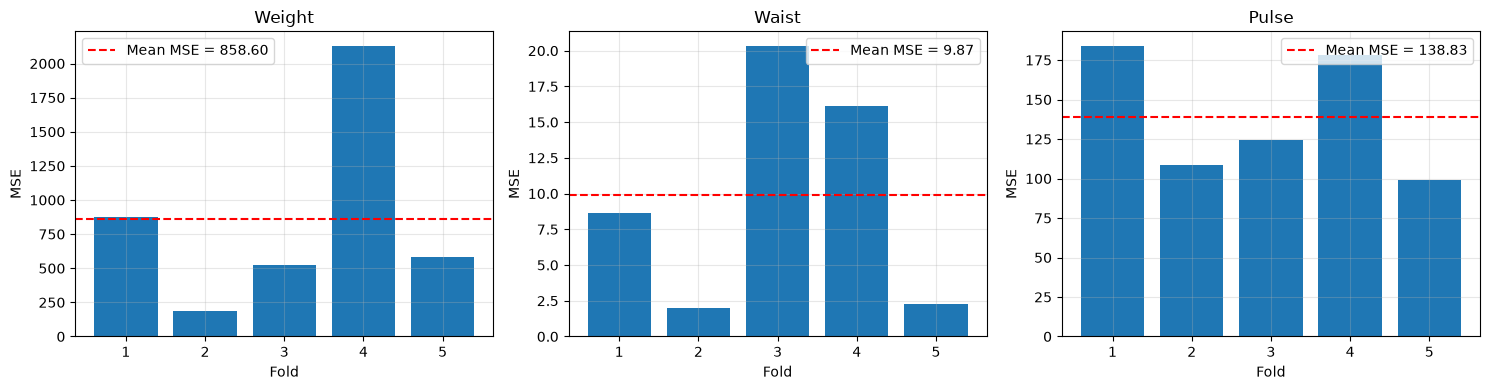

In [2]:
print("Обучение: 4 нейронов")
import matplotlib.pyplot as plt
import numpy as np
import torch

from torch import nn
from sklearn.datasets import load_linnerud
from sklearn.model_selection import KFold
from sklearn.preprocessing import StandardScaler


# 1. ЗАГРУЗКА ДАННЫХ

data = load_linnerud()

X = data.data
y = data.target

print("X:", X.shape)
print("y:", y.shape)


# 2. MLP

class MLP(nn.Module):
    def __init__(self):
        super().__init__()

        self.net = nn.Sequential(
             nn.Linear(3, 4),
             nn.ReLU(),
            nn.Linear(4, 3)
        )

    def forward(self, x):
        return self.net(x)


# 3. НАСТРОЙКИ K-FOLD

kfold = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

target_names = ["Weight", "Waist", "Pulse"]

fold_results = []

# Здесь сохраним прогноз для каждого из 20 объектов
all_predictions = np.zeros_like(y, dtype=float)


# 4. ЗАПУСК ПЯТИ ОБУЧЕНИЙ

for fold, (train_idx, val_idx) in enumerate(kfold.split(X), start=1):

    print(f"\n========== FOLD {fold} ==========")

    X_train = X[train_idx]
    X_val = X[val_idx]

    y_train = y[train_idx]
    y_val = y[val_idx]

    print("Train:", len(X_train))
    print("Validation:", len(X_val))

    # Нормализация только по обучающей части
    x_scaler = StandardScaler()
    y_scaler = StandardScaler()

    X_train = x_scaler.fit_transform(X_train)
    X_val = x_scaler.transform(X_val)

    y_train_scaled = y_scaler.fit_transform(y_train)

    # Преобразуем в тензоры
    X_train = torch.tensor(X_train, dtype=torch.float32)
    X_val = torch.tensor(X_val, dtype=torch.float32)

    y_train_scaled = torch.tensor(
        y_train_scaled,
        dtype=torch.float32
    )

    # Новая модель для каждого Fold
    torch.manual_seed(42 + fold)

    model = MLP()

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=0.01,
        weight_decay=0.01
    )

    loss_fn = nn.MSELoss()

    # 5. ОБУЧЕНИЕ
    model.train()

    for epoch in range(300):

        optimizer.zero_grad()

        predictions = model(X_train)

        loss = loss_fn(
            predictions,
            y_train_scaled
        )

        loss.backward()
        optimizer.step()

    # 6. ПРОВЕРКА
    model.eval()

    with torch.no_grad():
        val_predictions = model(X_val).numpy()

    # Возвращаем настоящие единицы измерения
    val_predictions = y_scaler.inverse_transform(
        val_predictions
    )

    all_predictions[val_idx] = val_predictions

    # MSE отдельно для каждого выхода
    mse = np.mean(
        (val_predictions - y_val) ** 2,
        axis=0
    )

    fold_results.append(mse)

    for name, value in zip(target_names, mse):
        print(f"{name}: MSE = {value:.4f}")


# 7. ИТОГИ K-FOLD

fold_results = np.array(fold_results)

print("\n========== ИТОГИ K-FOLD ==========")

for i, name in enumerate(target_names):

    mean_mse = fold_results[:, i].mean()
    std_mse = fold_results[:, i].std()

    print(
        f"{name}: "
        f"Mean MSE = {mean_mse:.4f} | "
        f"Std = {std_mse:.4f}"
    )
# 8. ГРАФИКИ K-FOLD

fig, axes = plt.subplots(
    1, 3,
    figsize=(15, 4)
)

for i, name in enumerate(target_names):

    mse_values = fold_results[:, i]

    axes[i].bar(
        range(1, 6),
        mse_values
    )

    # Среднее значение ошибки
    mean_mse = mse_values.mean()

    axes[i].axhline(
        mean_mse,
        color="red",
        linestyle="--",
        label=f"Mean MSE = {mean_mse:.2f}"
    )

    axes[i].set_title(name)
    axes[i].set_xlabel("Fold")
    axes[i].set_ylabel("MSE")

    axes[i].legend()
    axes[i].grid(alpha=0.3)

plt.tight_layout()
plt.show()



### K-Fold для сети 3 → 8 → 3

Повторяем то же разбиение `random_state=42`, те же 300 эпох, Adam и weight decay, увеличив ширину до восьми нейронов. Сравниваем MSE отдельно для Weight, Waist и Pulse.

Обучение: 8 нейронов
X: (20, 3)
y: (20, 3)

========== FOLD 1 ==========
Train: 16
Validation: 4
Weight: MSE = 596.7013
Waist: MSE = 5.4420
Pulse: MSE = 57.4301

========== FOLD 2 ==========
Train: 16
Validation: 4
Weight: MSE = 443.4624
Waist: MSE = 2.4156
Pulse: MSE = 233.3018

========== FOLD 3 ==========
Train: 16
Validation: 4
Weight: MSE = 1221.2191
Waist: MSE = 23.6941
Pulse: MSE = 120.3902

========== FOLD 4 ==========
Train: 16
Validation: 4
Weight: MSE = 788.7319
Waist: MSE = 5.5189
Pulse: MSE = 84.9663

========== FOLD 5 ==========
Train: 16
Validation: 4
Weight: MSE = 400.6822
Waist: MSE = 2.5943
Pulse: MSE = 61.9364

========== ИТОГИ K-FOLD ==========
Weight: Mean MSE = 690.1593 | Std = 298.3729
Waist: Mean MSE = 7.9330 | Std = 7.9923
Pulse: Mean MSE = 111.6049 | Std = 64.8056


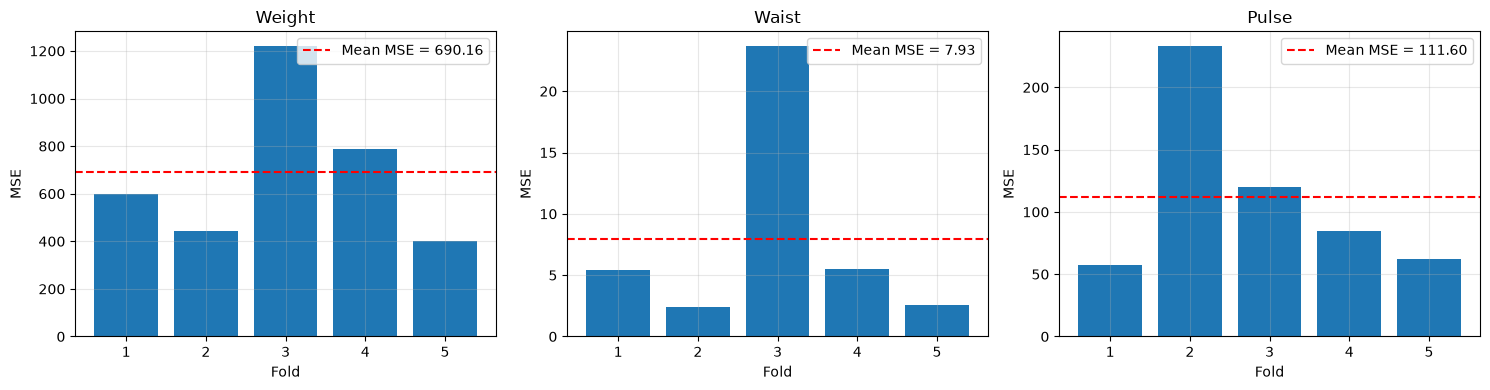

In [3]:
print("Обучение: 8 нейронов")
import matplotlib.pyplot as plt
import numpy as np
import torch

from torch import nn
from sklearn.datasets import load_linnerud
from sklearn.model_selection import KFold
from sklearn.preprocessing import StandardScaler


# 1. ЗАГРУЗКА ДАННЫХ

data = load_linnerud()

X = data.data
y = data.target

print("X:", X.shape)
print("y:", y.shape)


# 2. НАША MLP

class MLP(nn.Module):
    def __init__(self):
        super().__init__()

        self.net = nn.Sequential(
             nn.Linear(3, 8),
             nn.ReLU(),
            nn.Linear(8, 3)
        )

    def forward(self, x):
        return self.net(x)


# 3. НАСТРОЙКИ K-FOLD

kfold = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

target_names = ["Weight", "Waist", "Pulse"]

fold_results = []

# Здесь сохраним прогноз для каждого из 20 объектов
all_predictions = np.zeros_like(y, dtype=float)


# 4. ЗАПУСК ПЯТИ ОБУЧЕНИЙ

for fold, (train_idx, val_idx) in enumerate(kfold.split(X), start=1):

    print(f"\n========== FOLD {fold} ==========")

    X_train = X[train_idx]
    X_val = X[val_idx]

    y_train = y[train_idx]
    y_val = y[val_idx]

    print("Train:", len(X_train))
    print("Validation:", len(X_val))

    # Нормализация только по обучающей части
    x_scaler = StandardScaler()
    y_scaler = StandardScaler()

    X_train = x_scaler.fit_transform(X_train)
    X_val = x_scaler.transform(X_val)

    y_train_scaled = y_scaler.fit_transform(y_train)

    # Преобразуем в тензоры
    X_train = torch.tensor(X_train, dtype=torch.float32)
    X_val = torch.tensor(X_val, dtype=torch.float32)

    y_train_scaled = torch.tensor(
        y_train_scaled,
        dtype=torch.float32
    )

    # Новая модель для каждого Fold
    torch.manual_seed(42 + fold)

    model = MLP()

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=0.01,
        weight_decay=0.01
    )

    loss_fn = nn.MSELoss()

    # 5. ОБУЧЕНИЕ
    model.train()

    for epoch in range(300):

        optimizer.zero_grad()

        predictions = model(X_train)

        loss = loss_fn(
            predictions,
            y_train_scaled
        )

        loss.backward()
        optimizer.step()

    # 6. ПРОВЕРКА
    model.eval()

    with torch.no_grad():
        val_predictions = model(X_val).numpy()

    # Возвращаем настоящие единицы измерения
    val_predictions = y_scaler.inverse_transform(
        val_predictions
    )

    all_predictions[val_idx] = val_predictions

    # MSE отдельно для каждого выхода
    mse = np.mean(
        (val_predictions - y_val) ** 2,
        axis=0
    )

    fold_results.append(mse)

    for name, value in zip(target_names, mse):
        print(f"{name}: MSE = {value:.4f}")


# 7. ИТОГИ K-FOLD

fold_results = np.array(fold_results)

print("\n========== ИТОГИ K-FOLD ==========")

for i, name in enumerate(target_names):

    mean_mse = fold_results[:, i].mean()
    std_mse = fold_results[:, i].std()

    print(
        f"{name}: "
        f"Mean MSE = {mean_mse:.4f} | "
        f"Std = {std_mse:.4f}"
    )
# 8. ГРАФИКИ K-FOLD

fig, axes = plt.subplots(
    1, 3,
    figsize=(15, 4)
)

for i, name in enumerate(target_names):

    mse_values = fold_results[:, i]

    axes[i].bar(
        range(1, 6),
        mse_values
    )

    # Среднее значение ошибки
    mean_mse = mse_values.mean()

    axes[i].axhline(
        mean_mse,
        color="red",
        linestyle="--",
        label=f"Mean MSE = {mean_mse:.2f}"
    )

    axes[i].set_title(name)
    axes[i].set_xlabel("Fold")
    axes[i].set_ylabel("MSE")

    axes[i].legend()
    axes[i].grid(alpha=0.3)

plt.tight_layout()
plt.show()



### K-Fold для сети 3 → 16 → 3

Последний опыт использует 16 скрытых нейронов. Увеличение количества параметров может облегчить подгонку обучающих точек, но не гарантирует уменьшения ошибки на четырёх проверочных примерах в каждом Fold.

Обучение: 16 нейронов
X: (20, 3)
y: (20, 3)

========== FOLD 1 ==========
Train: 16
Validation: 4
Weight: MSE = 1377.8523
Waist: MSE = 6.9104
Pulse: MSE = 131.4562

========== FOLD 2 ==========
Train: 16
Validation: 4
Weight: MSE = 475.7254
Waist: MSE = 2.3956
Pulse: MSE = 256.0350

========== FOLD 3 ==========
Train: 16
Validation: 4
Weight: MSE = 716.8592
Waist: MSE = 19.5012
Pulse: MSE = 435.2878

========== FOLD 4 ==========
Train: 16
Validation: 4
Weight: MSE = 2477.5106
Waist: MSE = 10.5432
Pulse: MSE = 188.0637

========== FOLD 5 ==========
Train: 16
Validation: 4
Weight: MSE = 734.0182
Waist: MSE = 2.8229
Pulse: MSE = 99.8606

========== ИТОГИ K-FOLD ==========
Weight: Mean MSE = 1156.3931 | Std = 725.1613
Waist: Mean MSE = 8.4347 | Std = 6.2801
Pulse: Mean MSE = 222.1407 | Std = 119.0948


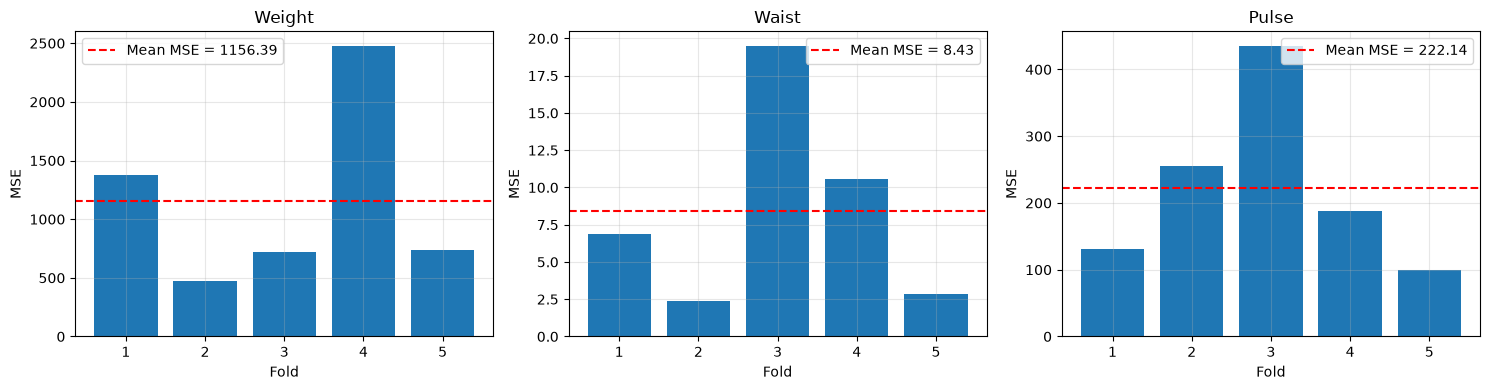

In [4]:
print("Обучение: 16 нейронов")
import matplotlib.pyplot as plt
import numpy as np
import torch

from torch import nn
from sklearn.datasets import load_linnerud
from sklearn.model_selection import KFold
from sklearn.preprocessing import StandardScaler


# 1. ЗАГРУЗКА ДАННЫХ

data = load_linnerud()

X = data.data
y = data.target

print("X:", X.shape)
print("y:", y.shape)


# 2. НАША MLP

class MLP(nn.Module):
    def __init__(self):
        super().__init__()

        self.net = nn.Sequential(
             nn.Linear(3, 16),
             nn.ReLU(),
            nn.Linear(16, 3)
        )

    def forward(self, x):
        return self.net(x)


# 3. НАСТРОЙКИ K-FOLD

kfold = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

target_names = ["Weight", "Waist", "Pulse"]

fold_results = []

# Здесь сохраним прогноз для каждого из 20 объектов
all_predictions = np.zeros_like(y, dtype=float)


# 4. ЗАПУСК ПЯТИ ОБУЧЕНИЙ

for fold, (train_idx, val_idx) in enumerate(kfold.split(X), start=1):

    print(f"\n========== FOLD {fold} ==========")

    X_train = X[train_idx]
    X_val = X[val_idx]

    y_train = y[train_idx]
    y_val = y[val_idx]

    print("Train:", len(X_train))
    print("Validation:", len(X_val))

    # Нормализация только по обучающей части
    x_scaler = StandardScaler()
    y_scaler = StandardScaler()

    X_train = x_scaler.fit_transform(X_train)
    X_val = x_scaler.transform(X_val)

    y_train_scaled = y_scaler.fit_transform(y_train)

    # Преобразуем в тензоры
    X_train = torch.tensor(X_train, dtype=torch.float32)
    X_val = torch.tensor(X_val, dtype=torch.float32)

    y_train_scaled = torch.tensor(
        y_train_scaled,
        dtype=torch.float32
    )

    # Новая модель для каждого Fold
    torch.manual_seed(42 + fold)

    model = MLP()

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=0.01,
        weight_decay=0.01
    )

    loss_fn = nn.MSELoss()

    # 5. ОБУЧЕНИЕ
    model.train()

    for epoch in range(300):

        optimizer.zero_grad()

        predictions = model(X_train)

        loss = loss_fn(
            predictions,
            y_train_scaled
        )

        loss.backward()
        optimizer.step()

    # 6. ПРОВЕРКА
    model.eval()

    with torch.no_grad():
        val_predictions = model(X_val).numpy()

    # Возвращаем настоящие единицы измерения
    val_predictions = y_scaler.inverse_transform(
        val_predictions
    )

    all_predictions[val_idx] = val_predictions

    # MSE отдельно для каждого выхода
    mse = np.mean(
        (val_predictions - y_val) ** 2,
        axis=0
    )

    fold_results.append(mse)

    for name, value in zip(target_names, mse):
        print(f"{name}: MSE = {value:.4f}")


# 7. ИТОГИ K-FOLD

fold_results = np.array(fold_results)

print("\n========== ИТОГИ K-FOLD ==========")

for i, name in enumerate(target_names):

    mean_mse = fold_results[:, i].mean()
    std_mse = fold_results[:, i].std()

    print(
        f"{name}: "
        f"Mean MSE = {mean_mse:.4f} | "
        f"Std = {std_mse:.4f}"
    )
# 8. ГРАФИКИ K-FOLD

fig, axes = plt.subplots(
    1, 3,
    figsize=(15, 4)
)

for i, name in enumerate(target_names):

    mse_values = fold_results[:, i]

    axes[i].bar(
        range(1, 6),
        mse_values
    )

    # Среднее значение ошибки
    mean_mse = mse_values.mean()

    axes[i].axhline(
        mean_mse,
        color="red",
        linestyle="--",
        label=f"Mean MSE = {mean_mse:.2f}"
    )

    axes[i].set_title(name)
    axes[i].set_xlabel("Fold")
    axes[i].set_ylabel("MSE")

    axes[i].legend()
    axes[i].grid(alpha=0.3)

plt.tight_layout()
plt.show()


### Сопоставляем средние ошибки и разброс

Сравниваем среднюю MSE и стандартное отклонение по пяти фолдам. Большой разброс показывает чувствительность к разбиению.

## Выводы

В сравнении ширина 8 даёт наименьшую среднюю MSE для трёх выходов. При этом разброс по фолдам остаётся большим: в каждом проверяется всего четыре объекта. Для независимой оценки выбранной архитектуры понадобится отдельная проверка.


## Полный код


In [ ]:
import copy
import numpy as np
import torch
from torch import nn
import matplotlib.pyplot as plt
torch.set_num_threads(1)
torch.manual_seed(42)
np.random.seed(42)
print("Обучение: 4 нейронов")
import matplotlib.pyplot as plt
import numpy as np
import torch

from torch import nn
from sklearn.datasets import load_linnerud
from sklearn.model_selection import KFold
from sklearn.preprocessing import StandardScaler


# 1. ЗАГРУЗКА ДАННЫХ

data = load_linnerud()

X = data.data
y = data.target

print("X:", X.shape)
print("y:", y.shape)


# 2. MLP

class MLP(nn.Module):
    def __init__(self):
        super().__init__()

        self.net = nn.Sequential(
             nn.Linear(3, 4),
             nn.ReLU(),
            nn.Linear(4, 3)
        )

    def forward(self, x):
        return self.net(x)


# 3. НАСТРОЙКИ K-FOLD

kfold = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

target_names = ["Weight", "Waist", "Pulse"]

fold_results = []

# Здесь сохраним прогноз для каждого из 20 объектов
all_predictions = np.zeros_like(y, dtype=float)


# 4. ЗАПУСК ПЯТИ ОБУЧЕНИЙ

for fold, (train_idx, val_idx) in enumerate(kfold.split(X), start=1):

    print(f"\n========== FOLD {fold} ==========")

    X_train = X[train_idx]
    X_val = X[val_idx]

    y_train = y[train_idx]
    y_val = y[val_idx]

    print("Train:", len(X_train))
    print("Validation:", len(X_val))

    # Нормализация только по обучающей части
    x_scaler = StandardScaler()
    y_scaler = StandardScaler()

    X_train = x_scaler.fit_transform(X_train)
    X_val = x_scaler.transform(X_val)

    y_train_scaled = y_scaler.fit_transform(y_train)

    # Преобразуем в тензоры
    X_train = torch.tensor(X_train, dtype=torch.float32)
    X_val = torch.tensor(X_val, dtype=torch.float32)

    y_train_scaled = torch.tensor(
        y_train_scaled,
        dtype=torch.float32
    )

    # Новая модель для каждого Fold
    torch.manual_seed(42 + fold)

    model = MLP()

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=0.01,
        weight_decay=0.01
    )

    loss_fn = nn.MSELoss()

    # 5. ОБУЧЕНИЕ
    model.train()

    for epoch in range(300):

        optimizer.zero_grad()

        predictions = model(X_train)

        loss = loss_fn(
            predictions,
            y_train_scaled
        )

        loss.backward()
        optimizer.step()

    # 6. ПРОВЕРКА
    model.eval()

    with torch.no_grad():
        val_predictions = model(X_val).numpy()

    # Возвращаем настоящие единицы измерения
    val_predictions = y_scaler.inverse_transform(
        val_predictions
    )

    all_predictions[val_idx] = val_predictions

    # MSE отдельно для каждого выхода
    mse = np.mean(
        (val_predictions - y_val) ** 2,
        axis=0
    )

    fold_results.append(mse)

    for name, value in zip(target_names, mse):
        print(f"{name}: MSE = {value:.4f}")


# 7. ИТОГИ K-FOLD

fold_results = np.array(fold_results)

print("\n========== ИТОГИ K-FOLD ==========")

for i, name in enumerate(target_names):

    mean_mse = fold_results[:, i].mean()
    std_mse = fold_results[:, i].std()

    print(
        f"{name}: "
        f"Mean MSE = {mean_mse:.4f} | "
        f"Std = {std_mse:.4f}"
    )
# 8. ГРАФИКИ K-FOLD

fig, axes = plt.subplots(
    1, 3,
    figsize=(15, 4)
)

for i, name in enumerate(target_names):

    mse_values = fold_results[:, i]

    axes[i].bar(
        range(1, 6),
        mse_values
    )

    # Среднее значение ошибки
    mean_mse = mse_values.mean()

    axes[i].axhline(
        mean_mse,
        color="red",
        linestyle="--",
        label=f"Mean MSE = {mean_mse:.2f}"
    )

    axes[i].set_title(name)
    axes[i].set_xlabel("Fold")
    axes[i].set_ylabel("MSE")

    axes[i].legend()
    axes[i].grid(alpha=0.3)

plt.tight_layout()
plt.show()

print("Обучение: 8 нейронов")
import matplotlib.pyplot as plt
import numpy as np
import torch

from torch import nn
from sklearn.datasets import load_linnerud
from sklearn.model_selection import KFold
from sklearn.preprocessing import StandardScaler


# 1. ЗАГРУЗКА ДАННЫХ

data = load_linnerud()

X = data.data
y = data.target

print("X:", X.shape)
print("y:", y.shape)


# 2. НАША MLP

class MLP(nn.Module):
    def __init__(self):
        super().__init__()

        self.net = nn.Sequential(
             nn.Linear(3, 8),
             nn.ReLU(),
            nn.Linear(8, 3)
        )

    def forward(self, x):
        return self.net(x)


# 3. НАСТРОЙКИ K-FOLD

kfold = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

target_names = ["Weight", "Waist", "Pulse"]

fold_results = []

# Здесь сохраним прогноз для каждого из 20 объектов
all_predictions = np.zeros_like(y, dtype=float)


# 4. ЗАПУСК ПЯТИ ОБУЧЕНИЙ

for fold, (train_idx, val_idx) in enumerate(kfold.split(X), start=1):

    print(f"\n========== FOLD {fold} ==========")

    X_train = X[train_idx]
    X_val = X[val_idx]

    y_train = y[train_idx]
    y_val = y[val_idx]

    print("Train:", len(X_train))
    print("Validation:", len(X_val))

    # Нормализация только по обучающей части
    x_scaler = StandardScaler()
    y_scaler = StandardScaler()

    X_train = x_scaler.fit_transform(X_train)
    X_val = x_scaler.transform(X_val)

    y_train_scaled = y_scaler.fit_transform(y_train)

    # Преобразуем в тензоры
    X_train = torch.tensor(X_train, dtype=torch.float32)
    X_val = torch.tensor(X_val, dtype=torch.float32)

    y_train_scaled = torch.tensor(
        y_train_scaled,
        dtype=torch.float32
    )

    # Новая модель для каждого Fold
    torch.manual_seed(42 + fold)

    model = MLP()

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=0.01,
        weight_decay=0.01
    )

    loss_fn = nn.MSELoss()

    # 5. ОБУЧЕНИЕ
    model.train()

    for epoch in range(300):

        optimizer.zero_grad()

        predictions = model(X_train)

        loss = loss_fn(
            predictions,
            y_train_scaled
        )

        loss.backward()
        optimizer.step()

    # 6. ПРОВЕРКА
    model.eval()

    with torch.no_grad():
        val_predictions = model(X_val).numpy()

    # Возвращаем настоящие единицы измерения
    val_predictions = y_scaler.inverse_transform(
        val_predictions
    )

    all_predictions[val_idx] = val_predictions

    # MSE отдельно для каждого выхода
    mse = np.mean(
        (val_predictions - y_val) ** 2,
        axis=0
    )

    fold_results.append(mse)

    for name, value in zip(target_names, mse):
        print(f"{name}: MSE = {value:.4f}")


# 7. ИТОГИ K-FOLD

fold_results = np.array(fold_results)

print("\n========== ИТОГИ K-FOLD ==========")

for i, name in enumerate(target_names):

    mean_mse = fold_results[:, i].mean()
    std_mse = fold_results[:, i].std()

    print(
        f"{name}: "
        f"Mean MSE = {mean_mse:.4f} | "
        f"Std = {std_mse:.4f}"
    )
# 8. ГРАФИКИ K-FOLD

fig, axes = plt.subplots(
    1, 3,
    figsize=(15, 4)
)

for i, name in enumerate(target_names):

    mse_values = fold_results[:, i]

    axes[i].bar(
        range(1, 6),
        mse_values
    )

    # Среднее значение ошибки
    mean_mse = mse_values.mean()

    axes[i].axhline(
        mean_mse,
        color="red",
        linestyle="--",
        label=f"Mean MSE = {mean_mse:.2f}"
    )

    axes[i].set_title(name)
    axes[i].set_xlabel("Fold")
    axes[i].set_ylabel("MSE")

    axes[i].legend()
    axes[i].grid(alpha=0.3)

plt.tight_layout()
plt.show()

print("Обучение: 16 нейронов")
import matplotlib.pyplot as plt
import numpy as np
import torch

from torch import nn
from sklearn.datasets import load_linnerud
from sklearn.model_selection import KFold
from sklearn.preprocessing import StandardScaler


# 1. ЗАГРУЗКА ДАННЫХ

data = load_linnerud()

X = data.data
y = data.target

print("X:", X.shape)
print("y:", y.shape)


# 2. НАША MLP

class MLP(nn.Module):
    def __init__(self):
        super().__init__()

        self.net = nn.Sequential(
             nn.Linear(3, 16),
             nn.ReLU(),
            nn.Linear(16, 3)
        )

    def forward(self, x):
        return self.net(x)


# 3. НАСТРОЙКИ K-FOLD

kfold = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

target_names = ["Weight", "Waist", "Pulse"]

fold_results = []

# Здесь сохраним прогноз для каждого из 20 объектов
all_predictions = np.zeros_like(y, dtype=float)


# 4. ЗАПУСК ПЯТИ ОБУЧЕНИЙ

for fold, (train_idx, val_idx) in enumerate(kfold.split(X), start=1):

    print(f"\n========== FOLD {fold} ==========")

    X_train = X[train_idx]
    X_val = X[val_idx]

    y_train = y[train_idx]
    y_val = y[val_idx]

    print("Train:", len(X_train))
    print("Validation:", len(X_val))

    # Нормализация только по обучающей части
    x_scaler = StandardScaler()
    y_scaler = StandardScaler()

    X_train = x_scaler.fit_transform(X_train)
    X_val = x_scaler.transform(X_val)

    y_train_scaled = y_scaler.fit_transform(y_train)

    # Преобразуем в тензоры
    X_train = torch.tensor(X_train, dtype=torch.float32)
    X_val = torch.tensor(X_val, dtype=torch.float32)

    y_train_scaled = torch.tensor(
        y_train_scaled,
        dtype=torch.float32
    )

    # Новая модель для каждого Fold
    torch.manual_seed(42 + fold)

    model = MLP()

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=0.01,
        weight_decay=0.01
    )

    loss_fn = nn.MSELoss()

    # 5. ОБУЧЕНИЕ
    model.train()

    for epoch in range(300):

        optimizer.zero_grad()

        predictions = model(X_train)

        loss = loss_fn(
            predictions,
            y_train_scaled
        )

        loss.backward()
        optimizer.step()

    # 6. ПРОВЕРКА
    model.eval()

    with torch.no_grad():
        val_predictions = model(X_val).numpy()

    # Возвращаем настоящие единицы измерения
    val_predictions = y_scaler.inverse_transform(
        val_predictions
    )

    all_predictions[val_idx] = val_predictions

    # MSE отдельно для каждого выхода
    mse = np.mean(
        (val_predictions - y_val) ** 2,
        axis=0
    )

    fold_results.append(mse)

    for name, value in zip(target_names, mse):
        print(f"{name}: MSE = {value:.4f}")


# 7. ИТОГИ K-FOLD

fold_results = np.array(fold_results)

print("\n========== ИТОГИ K-FOLD ==========")

for i, name in enumerate(target_names):

    mean_mse = fold_results[:, i].mean()
    std_mse = fold_results[:, i].std()

    print(
        f"{name}: "
        f"Mean MSE = {mean_mse:.4f} | "
        f"Std = {std_mse:.4f}"
    )
# 8. ГРАФИКИ K-FOLD

fig, axes = plt.subplots(
    1, 3,
    figsize=(15, 4)
)

for i, name in enumerate(target_names):

    mse_values = fold_results[:, i]

    axes[i].bar(
        range(1, 6),
        mse_values
    )

    # Среднее значение ошибки
    mean_mse = mse_values.mean()

    axes[i].axhline(
        mean_mse,
        color="red",
        linestyle="--",
        label=f"Mean MSE = {mean_mse:.2f}"
    )

    axes[i].set_title(name)
    axes[i].set_xlabel("Fold")
    axes[i].set_ylabel("MSE")

    axes[i].legend()
    axes[i].grid(alpha=0.3)

plt.tight_layout()
plt.show()
